Starting with getting the dataset

In [1]:
pip install ucimlrepo


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
online_shoppers_purchasing_intention_dataset = fetch_ucirepo(id=468) 
  
# data (as pandas dataframes) 
X = online_shoppers_purchasing_intention_dataset.data.features 
y = online_shoppers_purchasing_intention_dataset.data.targets 
  
# metadata 
print(online_shoppers_purchasing_intention_dataset.metadata) 
  
# variable information 
print(online_shoppers_purchasing_intention_dataset.variables) 


{'uci_id': 468, 'name': 'Online Shoppers Purchasing Intention Dataset', 'repository_url': 'https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/468/data.csv', 'abstract': 'Of the 12,330 sessions in the dataset,\n84.5% (10,422) were negative class samples that did not\nend with shopping, and the rest (1908) were positive class\nsamples ending with shopping.', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 12330, 'num_features': 17, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Revenue'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2018, 'last_updated': 'Thu Jan 11 2024', 'dataset_doi': '10.24432/C5F88Q', 'creators': ['C. Sakar', 'Yomi Kastro'], 'intro_paper': {'ID': 367, 'type': 'NATIVE', 'title': 'Real-time prediction of online shoppers’ pur

Import libraries

In [3]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn


Some EDA and feature engineering

In [7]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [5]:
y.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Revenue  12330 non-null  bool 
dtypes: bool(1)
memory usage: 12.2 KB


In [6]:
X.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
dtype: int64

In [20]:
X.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True


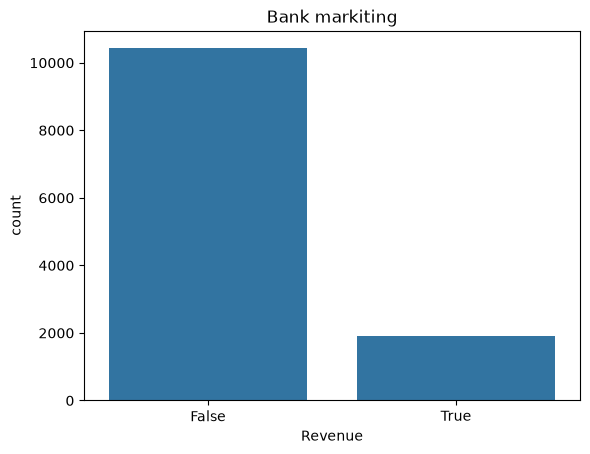

In [7]:
sns.countplot(data=X, x=y['Revenue'])
plt.title("Bank markiting")
plt.show()

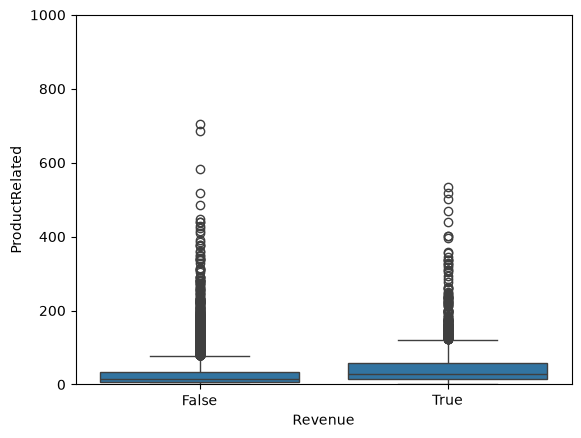

In [8]:
sns.boxplot(data=X, x=y['Revenue'], y="ProductRelated")
plt.ylim(0, 1000)
plt.show()

In [6]:
X['Weekend']=X['Weekend'].astype(str)

In [8]:
numerical_columns = [
    'Administrative',
    'Administrative_Duration',
    'Informational',
    'Informational_Duration',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues',
    'SpecialDay'
]

categorical_columns = [
    'Month',
    'OperatingSystems',
    'Browser',
    'Region',
    'TrafficType',
    'VisitorType',
    'Weekend'
]

In [9]:
df_corrmatrix=pd.DataFrame()
df_corrmatrix=X[numerical_columns].corr()
df_corrmatrix

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
Administrative,1.000000,0.601583,0.376850,0.255848,0.431119,0.373939,-0.223563,-0.316483,0.098990,-0.094778
Administrative_Duration,0.601583,1.000000,0.302710,0.238031,0.289087,0.355422,-0.144170,-0.205798,0.067608,-0.073304
Informational,0.376850,0.302710,1.000000,0.618955,0.374164,0.387505,-0.116114,-0.163666,0.048632,-0.048219
Informational_Duration,0.255848,0.238031,0.618955,1.000000,0.280046,0.347364,-0.074067,-0.105276,0.030861,-0.030577
ProductRelated,0.431119,0.289087,0.374164,0.280046,1.000000,0.860927,-0.204578,-0.292526,0.056282,-0.023958
ProductRelated_Duration,0.373939,0.355422,0.387505,0.347364,0.860927,1.000000,-0.184541,-0.251984,0.052823,-0.036380
BounceRates,-0.223563,-0.144170,-0.116114,-0.074067,-0.204578,-0.184541,1.000000,0.913004,-0.119386,0.072702
ExitRates,-0.316483,-0.205798,-0.163666,-0.105276,-0.292526,-0.251984,0.913004,1.000000,-0.174498,0.102242
PageValues,0.098990,0.067608,0.048632,0.030861,0.056282,0.052823,-0.119386,-0.174498,1.000000,-0.063541
SpecialDay,-0.094778,-0.073304,-0.048219,-0.030577,-0.023958,-0.036380,0.072702,0.102242,-0.063541,1.000000


In [10]:
from sklearn.model_selection import train_test_split

# First split: 70% Train, 30% Temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% Validation, 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [11]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dict = X_train[numerical_columns + categorical_columns].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = X_val[numerical_columns + categorical_columns].to_dict(orient='records')
X_val = dv.transform(val_dict)

test_dict = X_test[numerical_columns + categorical_columns].to_dict(orient='records')
X_test = dv.transform(test_dict)

In [12]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

print(type(X_train))

(8631, 29)
(1849, 29)
(1850, 29)
<class 'numpy.ndarray'>


In [13]:
print(dv.feature_names_)

['Administrative', 'Administrative_Duration', 'BounceRates', 'Browser', 'ExitRates', 'Informational', 'Informational_Duration', 'Month=Aug', 'Month=Dec', 'Month=Feb', 'Month=Jul', 'Month=June', 'Month=Mar', 'Month=May', 'Month=Nov', 'Month=Oct', 'Month=Sep', 'OperatingSystems', 'PageValues', 'ProductRelated', 'ProductRelated_Duration', 'Region', 'SpecialDay', 'TrafficType', 'VisitorType=New_Visitor', 'VisitorType=Other', 'VisitorType=Returning_Visitor', 'Weekend=False', 'Weekend=True']


Model comparession

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

lr = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

lr.fit(X_train, y_train.values.ravel())

y_pred = lr.predict(X_val)

print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

       False       0.94      0.88      0.91      1563
        True       0.53      0.72      0.61       286

    accuracy                           0.86      1849
   macro avg       0.74      0.80      0.76      1849
weighted avg       0.88      0.86      0.87      1849



/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

dt = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42,
    max_depth=10
)

dt.fit(X_train, y_train.values.ravel())

y_pred_dt = dt.predict(X_val)

print(classification_report(y_val, y_pred_dt))

              precision    recall  f1-score   support

       False       0.94      0.87      0.90      1563
        True       0.50      0.72      0.59       286

    accuracy                           0.84      1849
   macro avg       0.72      0.79      0.75      1849
weighted avg       0.87      0.84      0.85      1849



In [16]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train.values.ravel())

y_pred_rf = rf.predict(X_val)

print(classification_report(y_val, y_pred_rf))

              precision    recall  f1-score   support

       False       0.94      0.92      0.93      1563
        True       0.60      0.66      0.63       286

    accuracy                           0.88      1849
   macro avg       0.77      0.79      0.78      1849
weighted avg       0.89      0.88      0.88      1849



Doing Hyperparameter Tuning on random forest 

In [17]:
rf2 = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf2.fit(X_train, y_train.values.ravel())

y_pred_rf2 = rf2.predict(X_val)

print(classification_report(y_val, y_pred_rf2))

              precision    recall  f1-score   support

       False       0.95      0.88      0.92      1563
        True       0.54      0.75      0.63       286

    accuracy                           0.86      1849
   macro avg       0.74      0.82      0.77      1849
weighted avg       0.89      0.86      0.87      1849



The precision score got lowered after the hyperparameter tuning 

Trying different Thresholds

In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_proba = rf.predict_proba(X_val)[:, 1]

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred = (y_proba >= threshold)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_val, y_pred))
    print("Recall:", recall_score(y_val, y_pred))
    print("F1:", f1_score(y_val, y_pred))


Threshold: 0.3
Precision: 0.5119825708061002
Recall: 0.8216783216783217
F1: 0.6308724832214765

Threshold: 0.4
Precision: 0.5412371134020618
Recall: 0.7342657342657343
F1: 0.6231454005934718

Threshold: 0.5
Precision: 0.5974842767295597
Recall: 0.6643356643356644
F1: 0.6291390728476821

Threshold: 0.6
Precision: 0.6719367588932806
Recall: 0.5944055944055944
F1: 0.6307977736549165

Threshold: 0.7
Precision: 0.7529411764705882
Recall: 0.44755244755244755
F1: 0.5614035087719298
